In [2]:
# ============================================================
# PRODUCT RECOMMENDATION SYSTEM
# Algorithms: Apriori and Eclat
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [3]:
# ============================================================
# 1. LOAD DATASET
# ============================================================

# Dataset: Groceries dataset
# Expected columns: Member_number, Date, itemDescription

df = pd.read_csv("Groceries_dataset.csv")

print("Dataset Preview:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Dataset Preview:
   Member_number        Date   itemDescription
0           1808  21-07-2015    tropical fruit
1           2552  05-01-2015        whole milk
2           2300  19-09-2015         pip fruit
3           1187  12-12-2015  other vegetables
4           3037  01-02-2015        whole milk

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Member_number    38765 non-null  int64 
 1   Date             38765 non-null  object
 2   itemDescription  38765 non-null  object
dtypes: int64(1), object(2)
memory usage: 908.7+ KB
None

Missing Values:
Member_number      0
Date               0
itemDescription    0
dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [4]:
# ============================================================
# 2. DATA PREPROCESSING
# ============================================================

# Remove missing values and duplicate transaction-item entries

df = df.dropna(subset=["Member_number", "Date", "itemDescription"])

df["itemDescription"] = (
    df["itemDescription"].astype(str).str.strip().str.lower()
)

df = df.drop_duplicates(
    subset=["Member_number", "Date", "itemDescription"]
)

# Create transaction IDs using member number and date

df["Transaction_ID"] = (
    df["Member_number"].astype(str) + "_" + df["Date"].astype(str)
)

# Group purchased items into transactions

transactions = (
    df.groupby("Transaction_ID")["itemDescription"]
    .apply(list)
    .tolist()
)

print("\nTotal Transactions:", len(transactions))
print("Unique Products:", df["itemDescription"].nunique())


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Total Transactions: 14963
Unique Products: 167


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [5]:
# ============================================================
# 3. TRANSACTION ENCODING
# ============================================================

encoder = TransactionEncoder()

encoded_array = encoder.fit(transactions).transform(transactions)

basket = pd.DataFrame(
    encoded_array,
    columns=encoder.columns_
)

print("\nEncoded Transaction Matrix:")
print(basket.head())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Encoded Transaction Matrix:
   abrasive cleaner  artif. sweetener  baby cosmetics   bags  baking powder  \
0             False             False           False  False          False   
1             False             False           False  False          False   
2             False             False           False  False          False   
3             False             False           False  False          False   
4             False             False           False  False          False   

   bathroom cleaner   beef  berries  beverages  bottled beer  ...  uht-milk  \
0             False  False    False      False         False  ...     False   
1             False  False    False      False         False  ...     False   
2             False  False    False      False         False  ...     False   
3             False  False    False      False         False  ...     False   
4             False  False    False      False         False  ...     False   

   vinegar  waffles  

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [6]:
# ============================================================
# 4. APRIORI ALGORITHM
# ============================================================

MIN_SUPPORT = 0.001
MIN_CONFIDENCE = 0.10
MIN_LIFT = 1.0

frequent_itemsets_apriori = apriori(
    basket,
    min_support=MIN_SUPPORT,
    use_colnames=True
)

print("\nApriori Frequent Itemsets:")
print(frequent_itemsets_apriori.head(10))

# Generate association rules

rules_apriori = association_rules(
    frequent_itemsets_apriori,
    metric="confidence",
    min_threshold=MIN_CONFIDENCE
)

# Filter rules using lift

rules_apriori = rules_apriori[
    rules_apriori["lift"] >= MIN_LIFT
]

rules_apriori = rules_apriori.sort_values(
    by=["lift", "confidence"],
    ascending=False
)

print("\nApriori Association Rules:")
print(
    rules_apriori[
        ["antecedents", "consequents",
         "support", "confidence", "lift"]
    ].head(10)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Apriori Frequent Itemsets:
    support            itemsets
0  0.001470  (abrasive cleaner)
1  0.001938  (artif. sweetener)
2  0.008087     (baking powder)
3  0.001136  (bathroom cleaner)
4  0.033950              (beef)
5  0.021787           (berries)
6  0.016574         (beverages)
7  0.045312      (bottled beer)
8  0.060683     (bottled water)
9  0.002540            (brandy)

Apriori Association Rules:
               antecedents        consequents   support  confidence      lift
129   (yogurt, whole milk)          (sausage)  0.001470    0.131737  2.182917
128  (sausage, whole milk)           (yogurt)  0.001470    0.164179  1.911760
127      (sausage, yogurt)       (whole milk)  0.001470    0.255814  1.619866
31                 (flour)   (tropical fruit)  0.001069    0.109589  1.617141
88      (processed cheese)  (root vegetables)  0.001069    0.105263  1.513019
103          (soft cheese)           (yogurt)  0.001270    0.126667  1.474952
29             (detergent)           (yogurt) 

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [7]:



# ============================================================
# 5. ECLAT ALGORITHM
# ============================================================

def eclat(transactions, min_support=0.01):

    total_transactions = len(transactions)

    # Create vertical transaction ID representation

    item_tidsets = {}

    for tid, transaction in enumerate(transactions):

        for item in set(transaction):

            if item not in item_tidsets:
                item_tidsets[item] = set()

            item_tidsets[item].add(tid)

    frequent_itemsets = []

    # Recursive ECLAT search

    def recursive_search(prefix, items):

        for i, (item, tidset) in enumerate(items):

            new_prefix = prefix + (item,)

            support = len(tidset) / total_transactions

            if support >= min_support:

                frequent_itemsets.append({
                    "itemsets": frozenset(new_prefix),
                    "support": support
                })

                suffix = []

                for next_item, next_tidset in items[i + 1:]:

                    intersection = tidset & next_tidset

                    if (
                        len(intersection) / total_transactions
                        >= min_support
                    ):
                        suffix.append(
                            (next_item, intersection)
                        )

                recursive_search(new_prefix, suffix)

    sorted_items = sorted(
        item_tidsets.items(),
        key=lambda x: x[0]
    )

    recursive_search(tuple(), sorted_items)

    return pd.DataFrame(frequent_itemsets)


frequent_itemsets_eclat = eclat(
    transactions,
    min_support=MIN_SUPPORT
)

print("\nECLAT Frequent Itemsets:")
print(frequent_itemsets_eclat.head(10))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


ECLAT Frequent Itemsets:
                itemsets   support
0     (abrasive cleaner)  0.001470
1     (artif. sweetener)  0.001938
2        (baking powder)  0.008087
3     (bathroom cleaner)  0.001136
4                 (beef)  0.033950
5   (beef, bottled beer)  0.001069
6  (bottled water, beef)  0.001337
7    (brown bread, beef)  0.001537
8         (beef, butter)  0.001136
9    (canned beer, beef)  0.001002


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [8]:
# ============================================================
# 6. ASSOCIATION RULE GENERATION FOR ECLAT
# ============================================================

def generate_eclat_rules(itemsets, min_confidence=0.20):

    support_dict = {
        row["itemsets"]: row["support"]
        for _, row in itemsets.iterrows()
    }

    rules = []

    for itemset, support in support_dict.items():

        if len(itemset) < 2:
            continue

        from itertools import combinations

        for size in range(1, len(itemset)):

            for antecedent in combinations(itemset, size):

                antecedent = frozenset(antecedent)

                consequent = itemset - antecedent

                antecedent_support = support_dict.get(
                    antecedent, 0
                )

                consequent_support = support_dict.get(
                    consequent, 0
                )

                if antecedent_support == 0:
                    continue

                confidence = support / antecedent_support

                if confidence >= min_confidence:

                    lift = (
                        confidence / consequent_support
                        if consequent_support > 0
                        else 0
                    )

                    rules.append({
                        "antecedents": antecedent,
                        "consequents": consequent,
                        "support": support,
                        "confidence": confidence,
                        "lift": lift
                    })

    columns = ["antecedents", "consequents", "support", "confidence", "lift"]
    return pd.DataFrame(rules, columns=columns)


rules_eclat = generate_eclat_rules(
    frequent_itemsets_eclat,
    MIN_CONFIDENCE
)

if not rules_eclat.empty:
    rules_eclat = rules_eclat[
        rules_eclat["lift"] >= MIN_LIFT
    ].sort_values(
        by=["lift", "confidence"],
        ascending=False
    )

print("\nECLAT Association Rules:")
print(rules_eclat.head(10))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


ECLAT Association Rules:
               antecedents        consequents   support  confidence      lift
114   (yogurt, whole milk)          (sausage)  0.001470    0.131737  2.182917
113  (sausage, whole milk)           (yogurt)  0.001470    0.164179  1.911760
112      (sausage, yogurt)       (whole milk)  0.001470    0.255814  1.619866
31                 (flour)   (tropical fruit)  0.001069    0.109589  1.617141
95      (processed cheese)  (root vegetables)  0.001069    0.105263  1.513019
120          (soft cheese)           (yogurt)  0.001270    0.126667  1.474952
29             (detergent)           (yogurt)  0.001069    0.124031  1.444261
16           (chewing gum)           (yogurt)  0.001403    0.116667  1.358508
100  (sausage, rolls/buns)       (whole milk)  0.001136    0.212500  1.345594
94      (processed cheese)       (rolls/buns)  0.001470    0.144737  1.315734


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [9]:
# ============================================================
# 7. ALGORITHM COMPARISON
# ============================================================

print("\n========== ALGORITHM COMPARISON ==========")

print("Apriori Frequent Itemsets:",
      len(frequent_itemsets_apriori))

print("ECLAT Frequent Itemsets:",
      len(frequent_itemsets_eclat))

print("Apriori Association Rules:",
      len(rules_apriori))

print("ECLAT Association Rules:",
      len(rules_eclat))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


========== ALGORITHM COMPARISON ==========
Apriori Frequent Itemsets: 750
ECLAT Frequent Itemsets: 750
Apriori Association Rules: 37
ECLAT Association Rules: 37


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [10]:
# ============================================================
# 8. PRODUCT RECOMMENDATION FUNCTION
# ============================================================

def recommend_products(product, rules, top_n=5):

    product = product.lower()

    recommendations = []

    for _, rule in rules.iterrows():

        antecedents = rule["antecedents"]
        consequents = rule["consequents"]

        if product in antecedents:

            for item in consequents:

                recommendations.append({
                    "Product": item,
                    "Confidence": rule["confidence"],
                    "Lift": rule["lift"],
                    "Support": rule["support"]
                })

    if not recommendations:
        print("No recommendations found.")
        return pd.DataFrame()

    result = pd.DataFrame(recommendations)

    result = (
        result.groupby("Product", as_index=False)
        .agg({
            "Confidence": "max",
            "Lift": "max",
            "Support": "max"
        })
        .sort_values(
            by=["Lift", "Confidence"],
            ascending=False
        )
    )

    return result.head(top_n)


# Example recommendation

product = "whole milk"

recommendations = recommend_products(
    product,
    rules_apriori,
    top_n=5
)

print(f"\nRecommendations for {product}:")
print(recommendations)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Recommendations for whole milk:
      Product  Confidence      Lift   Support
1     sausage    0.131737  2.182917  0.001470
3      yogurt    0.164179  1.911760  0.001470
2        soda    0.119403  1.229612  0.001069
0  rolls/buns    0.126866  1.153275  0.001337


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

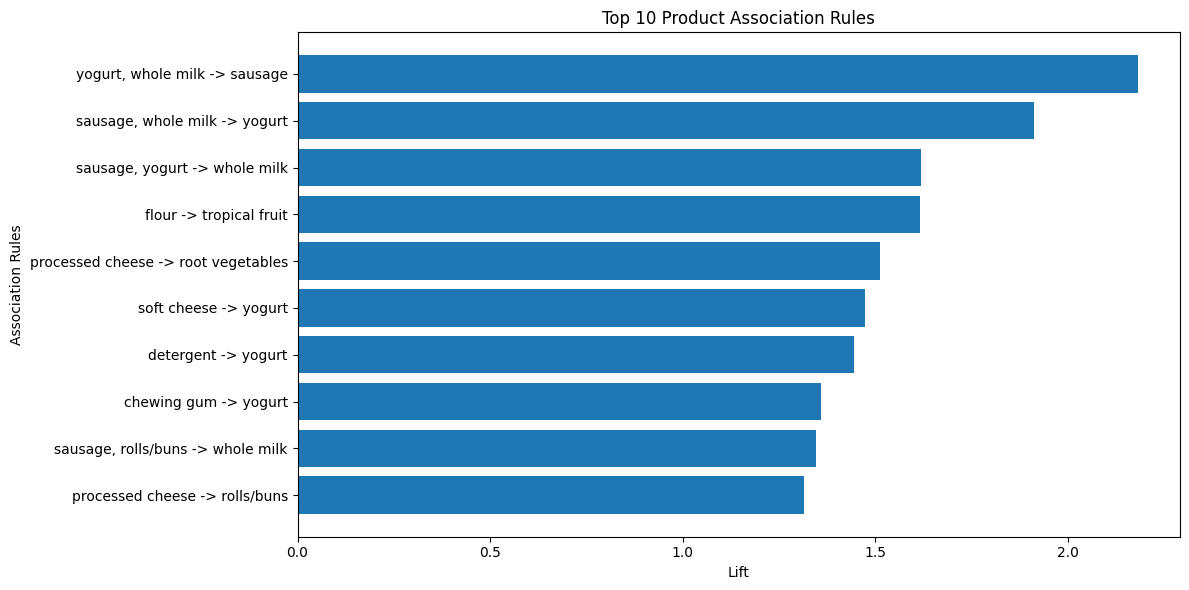

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [11]:
# ============================================================
# 9. VISUALIZATION
# ============================================================

if not rules_apriori.empty:

    top_rules = rules_apriori.head(10).copy()

    top_rules["Rule"] = top_rules.apply(
        lambda row: (
            ", ".join(row["antecedents"])
            + " -> "
            + ", ".join(row["consequents"])
        ),
        axis=1
    )

    plt.figure(figsize=(12, 6))

    plt.barh(
        top_rules["Rule"],
        top_rules["lift"]
    )

    plt.xlabel("Lift")
    plt.ylabel("Association Rules")
    plt.title("Top 10 Product Association Rules")
    plt.gca().invert_yaxis()

    plt.tight_layout()
    plt.show()

In [12]:


# ============================================================
# 10. EXPORT RESULTS
# ============================================================

frequent_itemsets_apriori.to_csv(
    "apriori_frequent_itemsets.csv",
    index=False
)

frequent_itemsets_eclat.to_csv(
    "eclat_frequent_itemsets.csv",
    index=False
)

rules_apriori.to_csv(
    "apriori_association_rules.csv",
    index=False
)

rules_eclat.to_csv(
    "eclat_association_rules.csv",
    index=False
)

print("\nProject execution completed successfully!")


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Project execution completed successfully!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [14]:
# Load and view the generated CSV files

files = [
    "apriori_frequent_itemsets.csv",
    "eclat_frequent_itemsets.csv",
    "apriori_association_rules.csv",
    "eclat_association_rules.csv"
]

for file_name in files:
    print(f"\n=== Preview of {file_name} ===")
    try:
        temp_df = pd.read_csv(file_name)
        print(f"Shape: {temp_df.shape}")
        print(temp_df.head())
    except Exception as e:
        print(f"Error reading {file_name}: {e}")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


=== Preview of apriori_frequent_itemsets.csv ===
Shape: (750, 2)
    support                         itemsets
0  0.001470  frozenset({'abrasive cleaner'})
1  0.001938  frozenset({'artif. sweetener'})
2  0.008087     frozenset({'baking powder'})
3  0.001136  frozenset({'bathroom cleaner'})
4  0.033950              frozenset({'beef'})

=== Preview of eclat_frequent_itemsets.csv ===
Shape: (750, 2)
                          itemsets   support
0  frozenset({'abrasive cleaner'})  0.001470
1  frozenset({'artif. sweetener'})  0.001938
2     frozenset({'baking powder'})  0.008087
3  frozenset({'bathroom cleaner'})  0.001136
4              frozenset({'beef'})  0.033950

=== Preview of apriori_association_rules.csv ===
Shape: (37, 14)
                            antecedents                     consequents  \
0   frozenset({'yogurt', 'whole milk'})          frozenset({'sausage'})   
1  frozenset({'sausage', 'whole milk'})           frozenset({'yogurt'})   
2      frozenset({'sausage', 'yogurt'})

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag